# Part C Storage Format Comparison
Use this notebook to collect evidence. Complete the marked answer cells in your own words.

In [1]:
from pathlib import Path
from time import perf_counter
from statistics import median
import pandas as pd

FILES = {
    'CSV': Path('02_retail_sales.csv'),
    'JSON': Path('03_retail_sales.json'),
    'Parquet': Path('04_retail_sales.parquet'),
}
for name, path in FILES.items():
    print(name, path.exists(), path.stat().st_size if path.exists() else 'missing')

CSV True 45506
JSON True 151870
Parquet True 23021


## Load the three equivalent datasets

In [2]:
loaders = {
    'CSV': lambda: pd.read_csv(FILES['CSV']),
    'JSON': lambda: pd.read_json(FILES['JSON'], lines=True),
    'Parquet': lambda: pd.read_parquet(FILES['Parquet']),
}
data = {name: loader() for name, loader in loaders.items()}
for name, frame in data.items():
    print(f'\n{name}: {frame.shape}')
    print(frame.dtypes)


CSV: (480, 15)
transaction_id      int64
order_id            int64
order_date         object
customer_id         int64
region             object
product_id          int64
product_name       object
category           object
quantity            int64
unit_price        float64
discount_rate     float64
payment_method     object
returned             bool
promotion_code     object
revenue           float64
dtype: object

JSON: (480, 15)
transaction_id      int64
order_id            int64
order_date         object
customer_id         int64
region             object
product_id          int64
product_name       object
category           object
quantity            int64
unit_price        float64
discount_rate     float64
payment_method     object
returned             bool
promotion_code     object
revenue           float64
dtype: object

Parquet: (480, 15)
transaction_id             int64
order_id                   int64
order_date        datetime64[ns]
customer_id                int64
region 

## Measure load time three times and report the median

In [3]:
timings = {}
for name, loader in loaders.items():
    runs = []
    for _ in range(3):
        start = perf_counter()
        _ = loader()
        runs.append((perf_counter() - start) * 1000)
    timings[name] = {'runs_ms': runs, 'median_ms': median(runs)}
timings

{'CSV': {'runs_ms': [8.25700000859797, 3.434099955484271, 3.2269000075757504],
  'median_ms': 3.434099955484271},
 'JSON': {'runs_ms': [11.936499970033765,
   11.689700186252594,
   9.240299928933382],
  'median_ms': 11.689700186252594},
 'Parquet': {'runs_ms': [4.491599975153804,
   5.17939985729754,
   4.738799994811416],
  'median_ms': 4.738799994811416}}

In [4]:
comparison = pd.DataFrame([
    {
        'format': name,
        'file_size_bytes': FILES[name].stat().st_size,
        'median_load_ms': timings[name]['median_ms'],
        'rows': data[name].shape[0],
        'columns': data[name].shape[1],
    }
    for name in FILES
])
comparison

,format,file_size_bytes,median_load_ms,rows,columns
0,CSV,45506,3.4341,480,15
1,JSON,151870,11.6897,480,15
2,Parquet,23021,4.7388,480,15


## C1 Identify data categories and schemas

The CSV file is structured because every row has the same columns in the same order and the header row lists the field names once.

The JSON file is semi-structured because information is organized using key-value pairs without a fixed, rigid schema.

The Parquet file is structured because it has a clearly defined schema that specifies every column name and data type.

| Feature | CSV | JSON | Parquet |
|---|---|---|---|
| Field names | Column names in the header row | Keys in each JSON object | Field names defined in the schema |
| Numbers | No quotes. Text and numbers look the same. | Numbers have no quotes. Text has quotes. | Explicit types such as int64 and double |
| Dates | Plain text `2025-01-01` (loads as object) | Quoted text with time (loads as object) | `timestamp[ns]` in the schema, loads as `datetime64[ns]` |
| Booleans | `False` in the raw data, loads as bool | `false` in the raw data, loads as bool | `bool` in the schema and pandas |
| Missing values | Empty field (`,,`) | `null` | A native null in a string column, with 226 nulls recorded in the file |

After loading, pandas shows the missing promotion codes from all three files as `NaN`, and `order_date` as `object` for CSV and JSON, so these differences are only visible in the raw files.

Parquet preserves data types most explicitly because it stores a schema that defines the data type of each field. This is evident in my results, where the `order_date` field is defined as `timestamp[ns]` and loaded into pandas as `datetime64[ns]`. In contrast, CSV and JSON load the same field as `object`. Although pandas correctly infers the numeric and Boolean types in all three datasets, Parquet explicitly records the data types in its schema, reducing reliance on type inference during loading.

In [5]:
comparison['median_load_ms'] = comparison['median_load_ms'].round(2)
comparison['order_date_type'] = [str(data[name]['order_date'].dtype) for name in comparison['format']]
comparison

,format,file_size_bytes,median_load_ms,rows,columns,order_date_type
0,CSV,45506,3.43,480,15,object
1,JSON,151870,11.69,480,15,object
2,Parquet,23021,4.74,480,15,datetime64[ns]


## C2 Measure and compare the formats

| Format | Size (bytes) | Median load (ms) | Rows | Columns | `order_date` type |
|---|---|---|---|---|---|
| CSV | 45,506 | 3.43 | 480 | 15 | object |
| JSON | 151,870 | 11.69 | 480 | 15 | object |
| Parquet | 23,021 | 4.74 | 480 | 15 | datetime64[ns] |

All other columns load with the same types in all three formats (int64, float64, bool, object).

**Difference 1: file size.** JSON has the largest file at 151,870 bytes, compared with 45,506 bytes for CSV and 23,021 bytes for Parquet. JSON is approximately 3.34 times the size of CSV partly because it stores field names with each record. Parquet is the smallest because it stores data by column in a compressed binary form, using about half the space of CSV.

**Difference 2: data type.** All three formats have 480 rows and 15 columns. However, Parquet preserves its data types explicitly through its schema. For example, the `order_date` column is stored as `timestamp[ns]` in Parquet and loaded into pandas as `datetime64[ns]`, whereas the CSV and JSON versions load this column as `object`.

**Variability.** The median load times were 3.43 ms for CSV, 11.69 ms for JSON and 4.74 ms for Parquet, so JSON was clearly the slowest and CSV and Parquet were much closer to each other. I kept all recorded runs. CSV's first run (8.26 ms) was much slower than its other two runs (3.43 and 3.23 ms), which is a typical warm-up effect, so I kept it and reported the median. JSON's runs (9.24 to 11.94 ms) and Parquet's runs (4.49 to 5.18 ms) were each fairly close together, with no clear outliers. Individual runs vary because of background processes, system activity and file access overhead, and the median reduces the effect of unusually high or low runs.

**Limitation.** The dataset contains only 480 rows, and the files may be cached by the operating system. The timing covers the whole DataFrame load (parsing, type conversion and memory allocation), not pure disk reading. The differences are also small in absolute terms, so these results illustrate differences between the formats but are not a benchmark for large datasets.

## C3 Recommend formats for workloads

**Recommended format for exchanging data with a simple external system: CSV.** I recommend CSV because it is human readable and simple, so almost any tool can open it, which makes it easy to use for flat tabular data.

**Recommended format for keeping nested event-style records: JSON.** I recommend JSON because it supports nested objects and arrays, and each record carries its own field names, so it suits event records with variable and hierarchical fields.

**Recommended format for repeated analytical queries over selected columns: Parquet.** I recommend Parquet because it is a column-oriented format, which allows analytical engines to read only the columns a query needs and avoid unnecessary data reading. It was also the smallest file in my results (23,021 bytes) and it kept `order_date` as a real date type.

## C4 Propose a partitioning plan

**Partition key:** I recommend partitioning by a month and year values derived from `order_date` (for example `order_month`, such as 2026-03), because the analysis is by month and year. Over five years this creates about 60 monthly partitions of roughly 8 million rows each, stored as one folder per month, for example `order_month=2026-03/`

**Partition pruning:** With partition pruning, a query for one month reads only that month's partition which is about 8 million rows and skips the other 59 partitions, instead of scanning all 500 million rows. This will make the query much faster and cheaper thereby rendering efficiency.

**A poor choice:** Partitioning by `transaction_id` would be a poor choice because it has high cardinality: in my data every row has its own value. With 500 million rows this would create up to 500 million partitions with one row each. This causes the small-file problem: a huge number of tiny files that are slow to list and read, and that waste storage and processing time.

## C5 Design a star schema

**Fact table: FactSales**

**Grain:** One row represents one retail transaction line for a particular product, customer, and order date.

The grain is important because it defines exactly what each row represents and prevents measures from being counted at inconsistent levels.

| Column | Purpose |
|---|---|
| `transaction_id` (PK) | Identifies the original transaction line |
| `customer_key` (FK) | Foreign key referencing `DimCustomer` |
| `product_key` (FK) | Foreign key referencing `DimProduct` |
| `date_key` (FK) | Foreign key referencing `DimDate` |
| `order_id` | Identifies the original order |
| `region` | Region of the sale |
| `quantity` | Numeric measure: number of units sold |
| `unit_price` | Numeric measure: price per unit |
| `revenue` | Numeric measure: revenue from the transaction line |
| `discount_rate` | Discount rate applied |
| `returned` | Indicates whether the item was returned |
| `payment_method` | Payment method used |
| `promotion_code` | Promotion associated with the transaction, if any |

`transaction_id` is unique for every row, so it serves as the fact table's primary key and no extra surrogate key is needed.

The three main numeric measures are `quantity`, `unit_price` and `revenue`. Quantity and revenue can be summed, while `unit_price` and `discount_rate` should be averaged because adding them together has no meaning.

**Dimension tables**

**DimCustomer** 
Stores information about the customer.

| Column | Purpose |
|---|---|
| `customer_key` (PK) | Unique warehouse-generated customer key |
| `customer_id` | Original customer identifier |

The primary key is `customer_key`, while `customer_id` retains the original identifier from the source dataset. 

**DimProduct** 
Stores descriptive information about each product.

| Column | Purpose |
|---|---|
| `product_key` (PK) | Unique warehouse-generated product key |
| `product_id` | Original product identifier |
| `product_name` | Product name |
| `category` | Product category |

The primary key is `product_key`.

**DimDate** 
Stores calendar information for analysing sales over time.

| Column | Purpose |
|---|---|
| `date_key` (PK) | Date identifier, such as `20250101` |
| `full_date` | Actual calendar date |
| `day` | Day of the month |
| `month` | Month number |
| `quarter` | Calendar quarter |
| `year` | Calendar year |

The primary key is date_key. The use of this dimension makes it very easy to group sales by day, month, year, quarter or yearly.

**Relationships and benefits**

Each dimension table has a one-to-many relationship with `FactSales`. The dimension table's primary key is referenced as a foreign key in `FactSales`.

This star schema simplifies analytical queries and allows sales to be analysed from different perspectives, such as sales region, product category and date. It also makes reporting easier because descriptive information is separated from measurable sales data.

**Denormalization.** Denormalization means storing descriptive attributes together (let us take for example, category repeated on every product row, or the date which is split into day, month and year) instead of splitting them into many small tables. The benefit is fewer joins and simpler queries, which could make analytical reporting easier and faster(hence efficiency). The cost would be repeated data, which requires more storage and increases the risk of inconsistent updates when the same information is changed in multiple places.


### Star Schema Diagram


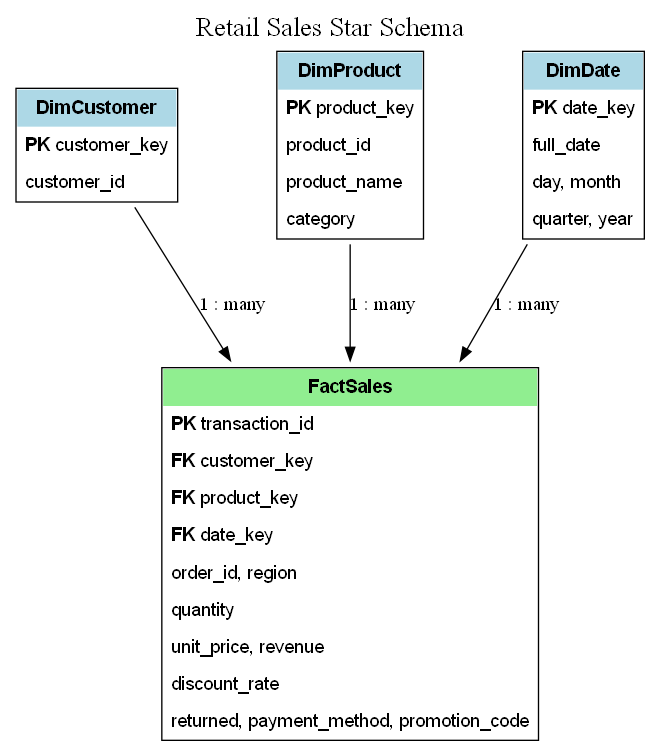

In [6]:
from IPython.display import Image, display

display(Image(filename="retail_star_schema.png"))